# Phase 6.3 - Clustering de Contexto Hibrido (v6.2 + fusion contextual)

Objetivo: mejorar la capa de "palabras/regimenes" combinando la base fuerte de `v6.2` con una capa contextual fusionada (`search_v6_3`).

Este notebook:
1. Ejecuta la generacion `v6.3` hibrida.
2. Compara metricas test entre `v6.2`, `v6.3_fused` y `v6.3_hybrid_pair`.
3. Muestra perfiles y transiciones de los tokens hibridos.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.')

# Ejecuta el pipeline completo de v6.3 hibrido
import importlib.util
script_path = ROOT / 'phases/phase06_context_regimes/run_v6_3_hybrid.py'
spec = importlib.util.spec_from_file_location('run_v6_3_hybrid', script_path)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
mod.main()

OUT_DIR = ROOT / 'phases/phase06_context_regimes/output_context_words_GBPUSD_v6_3_hybrid_from_v5_1'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_context_words_hybrid_summary_v6_3.json'
METRICS_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_metrics_v6_3.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_profile_v6_3.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_transition_matrix_v6_3.csv'

summary = json.loads(SUMMARY_JSON.read_text())
metrics = pd.read_csv(METRICS_CSV)
profile = pd.read_csv(PROFILE_CSV)
trans = pd.read_csv(TRANS_CSV, index_col=0)

print('summary ->', SUMMARY_JSON)
print('metrics ->', METRICS_CSV)
print('profile ->', PROFILE_CSV)
print('transitions ->', TRANS_CSV)

Saved:
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_3_hybrid_from_v5_1/GBPUSD_context_words_fused_v6_3.parquet
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_3_hybrid_from_v5_1/GBPUSD_context_words_hybrid_v6_3.parquet
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_3_hybrid_from_v5_1/GBPUSD_context_words_hybrid_metrics_v6_3.csv
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_3_hybrid_from_v5_1/GBPUSD_context_words_hybrid_summary_v6_3.json

Metrics:
                  model  n_test_rows  n_groups_active_test  coverage_test_active_groups  kw_pvalue_test  anova_pvalue_test  eta2_test
       phase6_v6_2_base          241                     7                     0.892116        0.001661           0.001609   0.096539
      phase6_v6_3_fused          241                     4                     1.000000        0.165106           0.327362   0.014420
phase6_v6_3_hybrid_pair          241                     4       

In [2]:
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

print('Selected fused config:')
print(summary['selected_fused_config'])
print('\nSplit counts:')
print(summary['split_counts_hybrid'])
print('\nMetrics table:')
display(metrics)

Selected fused config:
{'context_len': 24, 'ngram_range': [1, 3], 'min_df': 2, 'max_df': 0.95, 'svd_dim': 48, 'extra_name': 'delta', 'extra_weight': 0.5, 'best_k': 5, 'wf_score': 3.749213549629336, 'wf_eta': 0.030862417776829, 'wf_cov': 0.9701492537313432, 'wf_bal': 0.4638990172639571, 'diagnostic_test_eta2_from_search': 0.0144196160705651, 'diagnostic_test_kw_p_from_search': 0.1651060561656496}

Split counts:
{'train': 1100, 'val': 241, 'test': 241}

Metrics table:


,model,n_test_rows,n_groups_active_test,coverage_test_active_groups,kw_pvalue_test,anova_pvalue_test,eta2_test
0,phase6_v6_2_base,241,7,0.892116,0.001661,0.001609,0.096539
1,phase6_v6_3_fused,241,4,1.000000,0.165106,0.327362,0.014420
2,phase6_v6_3_hybrid_pair,241,4,0.369295,0.003405,0.008747,0.127232


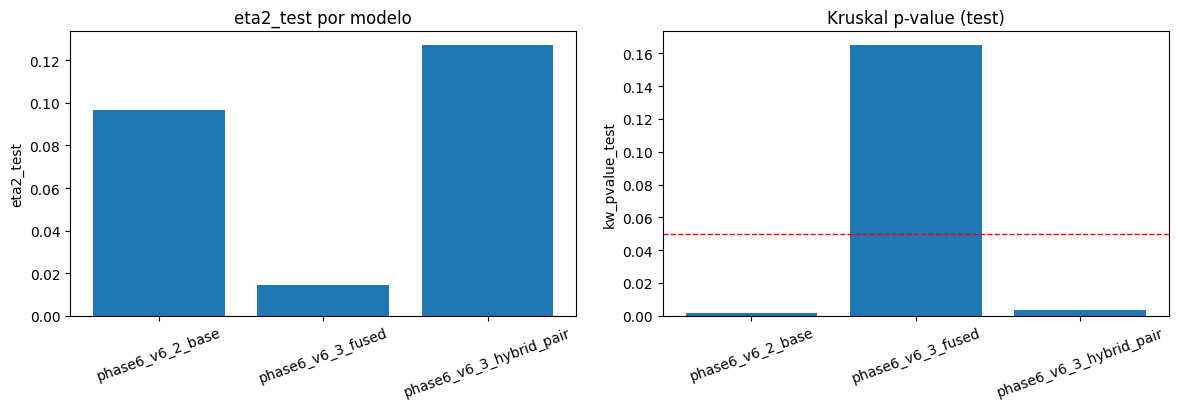

In [3]:
# Comparativo visual de eta2 y p-value
m = metrics.copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].bar(m['model'], m['eta2_test'])
axes[0].set_title('eta2_test por modelo')
axes[0].set_ylabel('eta2_test')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(m['model'], m['kw_pvalue_test'])
axes[1].axhline(0.05, color='red', linestyle='--', linewidth=1)
axes[1].set_title('Kruskal p-value (test)')
axes[1].set_ylabel('kw_pvalue_test')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [4]:
print('Top perfiles hibridos (test):')
display(profile.head(15))

print('Submatriz de transicion hibrida (primeras 12x12):')
display(trans.iloc[:12, :12])

Top perfiles hibridos (test):


,word_hybrid_token,n,mean_ret,median_ret,std_ret,t_like
0,w09_wf03,23,-55.156532,-51.599741,87.476806,-0.630527
1,w03_wf01,23,76.769590,74.599981,125.522855,0.611599
2,w08_wf02,22,-30.381680,-34.449697,101.071316,-0.300596
3,w02_wf01,21,-23.009550,-37.900209,207.709570,-0.110778
4,w00_wf04,19,-7.357911,9.399652,87.577319,-0.084016
5,w02_wf03,18,-5.866753,-10.100007,96.938340,-0.060520
6,w10_wf01,18,11.788872,20.200014,83.615067,0.140990
7,w07_wf03,16,-11.937618,-50.849915,123.103623,-0.096972
8,w07_wf01,15,-64.480225,-56.799650,105.294729,-0.612378
9,w04_wf03,14,10.178430,3.799200,102.165461,0.099627


Submatriz de transicion hibrida (primeras 12x12):


,w00_wf01,w00_wf03,w00_wf04,w01_wf02,w02_wf01,w02_wf03,w02_wf04,w03_wf01,w03_wf03,w03_wf04,w04_wf01,w04_wf02
word_hybrid_token,,,,,,,,,,,,
w00_wf01,0.931507,0.013699,0.027397,0.000000,0.000000,0.000000,0.000000,0.013699,0.013699,0.000000,0.000000,0.0
w00_wf03,0.024096,0.915663,0.000000,0.000000,0.000000,0.036145,0.012048,0.000000,0.000000,0.000000,0.000000,0.0
w00_wf04,0.000000,0.033333,0.916667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
w01_wf02,0.000000,0.000000,0.000000,0.956522,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
w02_wf01,0.017544,0.000000,0.000000,0.000000,0.789474,0.070175,0.017544,0.070175,0.000000,0.000000,0.000000,0.0
w02_wf03,0.000000,0.000000,0.000000,0.000000,0.057851,0.909091,0.000000,0.016529,0.000000,0.000000,0.000000,0.0
w02_wf04,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.800000,0.000000,0.000000,0.000000,0.000000,0.0
w03_wf01,0.000000,0.000000,0.000000,0.000000,0.018519,0.009259,0.000000,0.888889,0.000000,0.018519,0.000000,0.0
w03_wf03,0.000000,0.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.250000,0.250000,0.000000,0.000000,0.0
